## Results 2026-11-01 - tables and frontier figure

Tables and the size-frontier figure for `docs/results/2026-11-01-results.md`. Every value is read from the result artifacts under `data/results/workflows/model/`; nothing is copied from a document. The notebook is load-only: it loads no model and no dataset. A variant is off a frontier when another variant saves at least as many bytes and is strictly better on that metric, the rule of the 2026-10-15 snapshot.

setup

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

In [2]:
def find_project_root(start):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'mlp_replacement').is_dir():
            return candidate
    raise RuntimeError('Could not locate the repository root')


PROJECT_ROOT = find_project_root(Path.cwd())
RESULTS_ROOT = PROJECT_ROOT / 'data' / 'results' / 'workflows' / 'model'
FIGURE_DIRECTORY = PROJECT_ROOT / 'docs' / 'images' / 'results' / '2026-11-01'
SAVE_FIGURES = True
FIGURE_DPI = 150

FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)

artifacts and constants

In [3]:
SWIGLU_TARGETS = ['0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.75', '0.8']
ONE_BILLION_TARGETS = ['0.2', '0.5', '0.8']

# Quantization alone. Every INT3 QAT -001 run is invalid and INT3 QAT 1B is not
# rerun (decision log, 2026-10-25 and 2026-10-26). INT4 QAT uses the -002 reruns
# with the deployed-path quantizer (decision log, 2026-11-01).
QUANTIZATION_RUNS = {
    'Dense BF16': 'quantization-1/dense-001',
    'INT8 PTQ': 'quantization-1/int8-eval-001',
    'INT4 PTQ': 'quantization-1/int4-eval-001',
    'INT4 QAT 100M': 'quantization-1/qat-int4-100m-002',
    'INT4 QAT 1B': 'quantization-1/qat-int4-1b-002',
    'INT3 PTQ': 'quantization-2/int3-001',
    'INT3 QAT 100M': 'quantization-2/qat-int3-100m-002',
}
QAT_TRAINING_RUNS = {
    'INT4 QAT 100M': 'quantization-1/qat-int4-100m-002',
    'INT4 QAT 1B': 'quantization-1/qat-int4-1b-002',
    'INT3 QAT 100M': 'quantization-2/qat-int3-100m-002',
}

# SwiGLU alone at 1B, fitted arm: SwiGLU-7's S7-0 runs at 20/50% (their 8K KL
# was measured later by SwiGLU-9's reference-kl-001) and SwiGLU-9's fitted 80%.
SWIGLU_1B_FITTED_RUNS = {
    '0.2': 'swiglu-7/S7-0-target-0.2-run-001',
    '0.5': 'swiglu-7/S7-0-target-0.5-run-001',
    '0.8': 'swiglu-9/fitted-target-0.8-1b-run-001',
}
SWIGLU_1B_SLICE_RUNS = {target: f'swiglu-9/slice-target-{target}-1b-run-001' for target in ONE_BILLION_TARGETS}
REFERENCE_KL = 'swiglu-9/reference-kl-001'
PART_B_SUMMARY = 'swiglu-9/part-b-summary-001'
SWIGLU_8_PREPARE = 'swiglu-8/prepare-001'

# Stacking-1: every run except the invalid order-B INT3 -001 runs, which the
# -002 reruns replace (decision log, 2026-10-25).
STACKING_EXCLUDED = {f'b-fitted-{target}-100m-int3-001' for target in ONE_BILLION_TARGETS}
# Order-B INT4 -001 is superseded by its -002 rerun; order B at 1B is pending its own analysis.
STACKING_SKIPPED = {f'b-fitted-{target}-100m-int4-001' for target in ONE_BILLION_TARGETS} | {
    f'b-fitted-{target}-1b-int{bits}-001' for target in ONE_BILLION_TARGETS for bits in (3, 4)}
INVALID_INT3_QAT_RUNS = [
    'quantization-2/qat-int3-100m-001',
    'quantization-2/qat-int3-1b-001',
    *(f'stacking-1/{name}' for name in sorted(STACKING_EXCLUDED)),
]

TASK_METRICS = {'piqa': 'acc_norm', 'arc_easy': 'acc_norm', 'arc_challenge': 'acc_norm', 'winogrande': 'acc', 'hellaswag': 'acc_norm'}
GAP_BAR = 0.05  # SwiGLU-9 Part B bar (decision log, 2026-10-17)
REOPEN_MACRO_MARGIN = 0.01  # INT3 QAT 1B reopen condition (decision log, 2026-10-26)

# SmolLM2-1.7B shapes for the linear-FLOP count (decision log, 2026-11-01).
# The count is checked against every artifact's logical parameter count below.
HIDDEN = 2048
LAYERS = 24
DENSE_WIDTH = 8192
VOCABULARY = 49152
ATTENTION_PROJECTIONS = 4  # q, k, v, o, each HIDDEN x HIDDEN (32 query and 32 key-value heads)
NORM_PARAMETERS = (2 * LAYERS + 1) * HIDDEN

loading

In [4]:
def load_result(relative):
    return json.loads((RESULTS_ROOT / relative / 'result.json').read_text(encoding='utf-8'))


def task_macro(relative, tasks):
    accuracies = []
    for task, metric in TASK_METRICS.items():
        record = json.loads((RESULTS_ROOT / relative / tasks[task]['path']).read_text(encoding='utf-8'))
        accuracies.append(record['results'][task][f'{metric},none'])
    return sum(accuracies) / len(accuracies)


def linear_weights(widths):
    """Weights of every linear projection: attention, the MLPs at the given widths, and the tied output head."""
    attention = LAYERS * ATTENTION_PROJECTIONS * HIDDEN * HIDDEN
    mlp = sum(3 * HIDDEN * width for width in widths)
    return attention + mlp + VOCABULARY * HIDDEN


def percent_label(target):
    return f'{round(float(target) * 100)}%'


prepare = load_result(SWIGLU_8_PREPARE)['results']
# Both SwiGLU-8 arms of a target share one selection (decision log, 2026-10-10).
swiglu_widths = {
    target: [DENSE_WIDTH] + [row['replacement_width'] for row in prepare['starts'][f'fitted:{target}']['allocation']] + [DENSE_WIDTH]
    for target in SWIGLU_TARGETS
}
DENSE_BYTES = load_result(QUANTIZATION_RUNS['Dense BF16'])['results']['footprint']['weight_storage_bytes']
print('dense weight bytes:', DENSE_BYTES)

dense weight bytes: 3422752768


In [5]:
records = []

for label, relative in QUANTIZATION_RUNS.items():
    result = load_result(relative)['results']
    evaluation = result['evaluation']
    calculated = result.get('calculated_footprint')
    weight_bytes = calculated['weight_bytes'] if calculated else result['footprint']['weight_storage_bytes']
    records.append({
        'variant': label,
        'method': 'dense' if label == 'Dense BF16' else 'quantization',
        'arm': None, 'order': None, 'target': None, 'bits': None,
        'budget': None if 'PTQ' in label or label == 'Dense BF16' else label.split()[-1],
        'byte_basis': 'calculated' if calculated else 'measured',
        'byte_saving': 1 - weight_bytes / DENSE_BYTES,
        'kl_8k': evaluation['kl']['kl'],
        'test_ppl_8k': evaluation['likelihood']['test-8192']['perplexity'],
        'macro': task_macro(relative, evaluation['tasks']),
        'widths': [DENSE_WIDTH] * LAYERS,
        'logical_parameters': result['footprint']['logical_parameters'],
        'source': relative,
    })

reference_kl = load_result(REFERENCE_KL)['results']['targets']
swiglu_runs = [
    (arm, '100M', target, f'swiglu-8/{arm}-target-{target}-run-001')
    for arm in ('fitted', 'slice') for target in SWIGLU_TARGETS
]
swiglu_runs += [('fitted', '1B', target, relative) for target, relative in SWIGLU_1B_FITTED_RUNS.items()]
swiglu_runs += [('slice', '1B', target, relative) for target, relative in SWIGLU_1B_SLICE_RUNS.items()]
for arm, budget, target, relative in swiglu_runs:
    evaluation = load_result(relative)['results']['evaluation']
    teacher_kl = evaluation.get('teacher_kl_8192') or reference_kl[target]['teacher_kl_8192']
    records.append({
        'variant': f'SwiGLU {percent_label(target)}' + (' slice-only' if arm == 'slice' else '') + (' 1B' if budget == '1B' else ''),
        'method': 'swiglu', 'arm': arm, 'order': None, 'target': target, 'bits': None, 'budget': budget,
        'byte_basis': 'measured',
        'byte_saving': 1 - evaluation['footprint']['parameter_bytes'] / DENSE_BYTES,
        'kl_8k': teacher_kl['kl'],
        'test_ppl_8k': evaluation['likelihood']['test-8192']['perplexity'],
        'macro': evaluation['comparison_to_dense']['macro_accuracy'],
        'widths': swiglu_widths[target],
        'logical_parameters': evaluation['footprint']['parameters'],
        'source': relative,
    })

for path in sorted((RESULTS_ROOT / 'stacking-1').glob('*/result.json')):
    name = path.parent.name
    if name in STACKING_EXCLUDED | STACKING_SKIPPED:
        continue
    record = json.loads(path.read_text(encoding='utf-8'))
    if record['status'] != 'completed':
        raise RuntimeError(f'{name} is {record["status"]}')
    result = record['results']
    evaluation = result['evaluation']
    order, arm, target, budget, bits, _ = name.split('-')
    # padding.rows lists every replaced layer with its deployed (padded) width; other layers are dense.
    deployed = {int(row['path'].split('.')[2]): row['width'] for row in result['padding']['rows']}
    widths = [deployed.get(layer, DENSE_WIDTH) for layer in range(LAYERS)]
    records.append({
        'variant': f'{order.upper()} {percent_label(target)}' + (' slice-only' if arm == 'slice' else '') + f' {bits.upper()}' + (' 1B' if budget == '1b' else ''),
        'method': 'stacked', 'arm': arm, 'order': order.upper(), 'target': target, 'bits': bits.upper(), 'budget': budget.upper(),
        'byte_basis': evaluation['footprint']['frontier_basis'],
        'byte_saving': evaluation['footprint']['whole_model_byte_saving'],
        'kl_8k': evaluation['teacher_kl_8192']['kl'],
        'test_ppl_8k': evaluation['likelihood']['test-8192']['perplexity'],
        'macro': evaluation['comparison_to_dense']['macro_accuracy'],
        'widths': widths,
        'logical_parameters': evaluation['footprint']['logical_parameters'],
        'source': f'stacking-1/{name}',
    })

variants = pd.DataFrame(records)
variants['linear_flops'] = 2 * variants['widths'].map(linear_weights)
variants['flop_saving'] = 1 - variants['linear_flops'] / variants.loc[variants['variant'] == 'Dense BF16', 'linear_flops'].item()
# Linear weights plus norm weights must equal each artifact's logical parameter count.
parameter_mismatch = variants['widths'].map(linear_weights) + NORM_PARAMETERS - variants['logical_parameters']
print(len(variants), 'variants; largest parameter-count mismatch:', parameter_mismatch.abs().max())
dense_macro_implied = (variants.loc[variants['source'] == 'swiglu-8/fitted-target-0.2-run-001', 'macro'].item()
                       - load_result('swiglu-8/fitted-target-0.2-run-001')['results']['evaluation']['comparison_to_dense']['macro_delta'])
print('dense macro, Quantization-1 task files:', round(variants.loc[variants['variant'] == 'Dense BF16', 'macro'].item(), 6),
      '| implied by SwiGLU-8 comparison_to_dense:', round(dense_macro_implied, 6))

77 variants; largest parameter-count mismatch: 0
dense macro, Quantization-1 task files: 0.671414 | implied by SwiGLU-8 comparison_to_dense: 0.671414


In [6]:
def formatted(table, columns):
    shown = table[columns].copy()
    for column in columns:
        if column in ('byte_saving', 'flop_saving'):
            shown[column] = shown[column].map(lambda value: f'{100 * value:.1f}%')
        elif column == 'macro':
            shown[column] = shown[column].map(lambda value: f'{100 * value:.2f}%')
        elif column == 'kl_8k':
            # The dense model's KL against itself is -1.5e-9, numerical noise around zero.
            shown[column] = shown[column].map(lambda value: f'{value:.4f}'.replace('-0.0000', '0.0000'))
        elif column == 'test_ppl_8k':
            shown[column] = shown[column].map(lambda value: f'{value:.2f}')
        elif column == 'linear_flops':
            shown[column] = shown[column].map(lambda value: f'{value / 1e9:.2f}G')
    return shown


TABLE_COLUMNS = ['variant', 'byte_basis', 'byte_saving', 'kl_8k', 'test_ppl_8k', 'macro', 'linear_flops', 'flop_saving']
formatted(variants.sort_values(['byte_saving', 'kl_8k']), TABLE_COLUMNS + ['source'])

,variant,byte_basis,byte_saving,kl_8k,test_ppl_8k,macro,linear_flops,flop_saving,source
0,Dense BF16,measured,0.0%,0.0000,6.93,67.14%,3.42G,0.0%,quantization-1/dense-001
23,SwiGLU 20% 1B,measured,12.9%,0.0582,7.56,63.95%,2.98G,12.9%,swiglu-7/S7-0-target-0.2-run-001
26,SwiGLU 20% slice-only 1B,measured,12.9%,0.0598,7.56,63.69%,2.98G,12.9%,swiglu-9/slice-target-0.2-1b-run-001
7,SwiGLU 20%,measured,12.9%,0.0787,7.73,62.80%,2.98G,12.9%,swiglu-8/fitted-target-0.2-run-001
15,SwiGLU 20% slice-only,measured,12.9%,0.0887,7.79,61.86%,2.98G,12.9%,swiglu-8/slice-target-0.2-run-001
8,SwiGLU 30%,measured,19.4%,0.1161,8.17,60.70%,2.76G,19.4%,swiglu-8/fitted-target-0.3-run-001
16,SwiGLU 30% slice-only,measured,19.4%,0.1288,8.26,60.00%,2.76G,19.4%,swiglu-8/slice-target-0.3-run-001
9,SwiGLU 40%,measured,25.9%,0.1701,8.84,58.13%,2.54G,25.9%,swiglu-8/fitted-target-0.4-run-001
17,SwiGLU 40% slice-only,measured,25.9%,0.1883,8.99,58.14%,2.54G,25.9%,swiglu-8/slice-target-0.4-run-001
1,INT8 PTQ,measured,32.3%,0.0030,6.94,66.99%,3.42G,0.0%,quantization-1/int8-eval-001


size frontier

In [7]:
FRONTIER_METRICS = {'kl_8k': True, 'test_ppl_8k': True, 'macro': False}  # metric: lower is better


def dominators(points, point, metric, lower_is_better):
    better = points[metric] < point[metric] if lower_is_better else points[metric] > point[metric]
    return points[(points['byte_saving'] >= point['byte_saving']) & better]


def frontier_flags(points):
    flags = pd.DataFrame(index=points.index)
    for metric, lower_is_better in FRONTIER_METRICS.items():
        flags[metric] = [dominators(points, point, metric, lower_is_better).empty for _, point in points.iterrows()]
        # The nearest model that beats it: smallest saving among its dominators, then the best metric.
        flags[f'beaten_by_{metric}'] = [
            None if frontier else dominators(points, point, metric, lower_is_better)
            .sort_values(['byte_saving', metric], ascending=[True, lower_is_better])['variant'].iloc[0]
            for (_, point), frontier in zip(points.iterrows(), flags[metric])
        ]
    return flags


# Slice-only models are the local-fitting control arm (section 3), not frontier candidates.
candidates = variants[variants['arm'] != 'slice'].copy()
candidates = candidates.join(frontier_flags(candidates).add_prefix('frontier_'))
with_slice = variants.join(frontier_flags(variants).add_prefix('frontier_'))
for metric in FRONTIER_METRICS:
    changed = set(candidates.loc[candidates[f'frontier_{metric}'], 'variant']) ^ set(with_slice.loc[with_slice[f'frontier_{metric}'], 'variant'])
    print(f'{metric}: frontier members changed by adding the slice-only models: {sorted(changed) or "none"}')

on_any = candidates[candidates[[f'frontier_{metric}' for metric in FRONTIER_METRICS]].any(axis=1)].sort_values('byte_saving').copy()
on_any['on_frontier'] = on_any.apply(
    lambda row: ', '.join(name for metric, name in [('kl_8k', 'KL'), ('test_ppl_8k', 'PPL'), ('macro', 'macro')] if row[f'frontier_{metric}']),
    axis=1,
)
formatted(on_any, TABLE_COLUMNS + ['on_frontier'])

kl_8k: frontier members changed by adding the slice-only models: none
test_ppl_8k: frontier members changed by adding the slice-only models: none
macro: frontier members changed by adding the slice-only models: none


,variant,byte_basis,byte_saving,kl_8k,test_ppl_8k,macro,linear_flops,flop_saving,on_frontier
0,Dense BF16,measured,0.0%,0.0000,6.93,67.14%,3.42G,0.0%,"KL, PPL, macro"
1,INT8 PTQ,measured,32.3%,0.0030,6.94,66.99%,3.42G,0.0%,"KL, PPL"
3,INT4 QAT 100M,measured,47.5%,0.0291,7.17,65.87%,3.42G,0.0%,"KL, PPL"
4,INT4 QAT 1B,measured,47.5%,0.0297,7.30,67.06%,3.42G,0.0%,macro
6,INT3 QAT 100M,calculated,51.6%,0.0804,7.77,64.30%,3.42G,0.0%,"KL, PPL, macro"
32,A 20% INT3 1B,calculated,54.2%,0.2656,9.22,60.57%,2.98G,12.9%,macro
71,B 20% INT3,calculated,54.2%,0.1612,8.68,60.15%,2.98G,12.9%,"KL, PPL"
45,A 50% INT4 1B,measured,56.1%,0.2386,9.55,57.31%,2.32G,32.4%,"KL, PPL, macro"
44,A 50% INT3 1B,calculated,58.1%,0.3600,10.89,56.59%,2.32G,32.4%,macro
73,B 50% INT3,calculated,58.1%,0.2881,10.50,53.95%,2.32G,32.4%,"KL, PPL"


In [8]:
REFERENCE_VARIANTS = [
    'INT4 PTQ', 'INT3 PTQ', 'A 20% INT8',
    'SwiGLU 20%', 'SwiGLU 50%', 'SwiGLU 80%', 'SwiGLU 20% 1B', 'SwiGLU 50% 1B', 'SwiGLU 80% 1B',
]
references = candidates.set_index('variant').loc[REFERENCE_VARIANTS].reset_index()
formatted(references, TABLE_COLUMNS).assign(
    beaten_by_kl=references['frontier_beaten_by_kl_8k'],
    beaten_by_ppl=references['frontier_beaten_by_test_ppl_8k'],
    beaten_by_macro=references['frontier_beaten_by_macro'],
)

,variant,byte_basis,byte_saving,kl_8k,test_ppl_8k,macro,linear_flops,flop_saving,beaten_by_kl,beaten_by_ppl,beaten_by_macro
0,INT4 PTQ,measured,47.5%,0.0896,7.42,64.95%,3.42G,0.0%,INT4 QAT 100M,INT4 QAT 100M,INT4 QAT 1B
1,INT3 PTQ,calculated,51.6%,0.2226,8.56,63.97%,3.42G,0.0%,INT3 QAT 100M,INT3 QAT 100M,INT3 QAT 100M
2,A 20% INT8,measured,38.8%,0.0805,7.74,62.92%,2.98G,12.9%,A 20% INT8 1B,A 20% INT8 1B,A 20% INT8 1B
3,SwiGLU 20%,measured,12.9%,0.0787,7.73,62.80%,2.98G,12.9%,SwiGLU 20% 1B,SwiGLU 20% 1B,SwiGLU 20% 1B
4,SwiGLU 50%,measured,32.4%,0.2288,9.64,55.65%,2.32G,32.4%,SwiGLU 50% 1B,SwiGLU 50% 1B,SwiGLU 50% 1B
5,SwiGLU 80%,measured,51.8%,0.5433,14.97,46.99%,1.65G,51.8%,SwiGLU 80% 1B,SwiGLU 80% 1B,SwiGLU 80% 1B
6,SwiGLU 20% 1B,measured,12.9%,0.0582,7.56,63.95%,2.98G,12.9%,INT8 PTQ,INT8 PTQ,INT8 PTQ
7,SwiGLU 50% 1B,measured,32.4%,0.1578,8.86,58.49%,2.32G,32.4%,A 20% INT8 1B,A 20% INT8 1B,A 20% INT8 1B
8,SwiGLU 80% 1B,measured,51.8%,0.3752,12.41,50.51%,1.65G,51.8%,A 30% INT4,A 30% INT4,A 30% INT4


plot style

In [9]:
SURFACE = '#fcfcfb'
TEXT = '#0b0b0b'
TEXT_SECONDARY = '#52514e'
GRID = '#e1e0d9'
FRONTIER = '#8a8984'
DOMINATED_FILL = '#efeeeb'

# Hue = method, marker = stacking order, hollow = 1B recovery. Three hues keep
# every pair distinguishable in a scatter (dataviz validator, all pairs, light).
QUANTIZATION_COLOR = '#eb6834'
SWIGLU_COLOR = '#2a78d6'
STACKED_COLOR = '#1baf7a'
SERIES = [
    ('Dense BF16', lambda table: table['method'] == 'dense', '#52514e', '*', 190, True),
    ('Quantization alone', lambda table: table['method'] == 'quantization', QUANTIZATION_COLOR, 's', 60, True),
    ('SwiGLU alone, 100M', lambda table: (table['method'] == 'swiglu') & (table['budget'] == '100M'), SWIGLU_COLOR, 'o', 60, True),
    ('SwiGLU alone, 1B', lambda table: (table['method'] == 'swiglu') & (table['budget'] == '1B'), SWIGLU_COLOR, 'o', 60, False),
    ('Stacked, order A, 100M', lambda table: (table['order'] == 'A') & (table['budget'] == '100M'), STACKED_COLOR, '^', 70, True),
    ('Stacked, order A, 1B', lambda table: (table['order'] == 'A') & (table['budget'] == '1B'), STACKED_COLOR, '^', 70, False),
    ('Stacked, order B, 100M', lambda table: table['order'] == 'B', STACKED_COLOR, 'D', 52, True),
]

size frontier, 8K KL

KL frontier: ['Dense BF16', 'INT8 PTQ', 'INT4 QAT 100M', 'INT3 QAT 100M', 'B 20% INT3', 'A 50% INT4 1B', 'B 50% INT3', 'A 80% INT8 1B', 'A 80% INT4 1B', 'B 80% INT3']


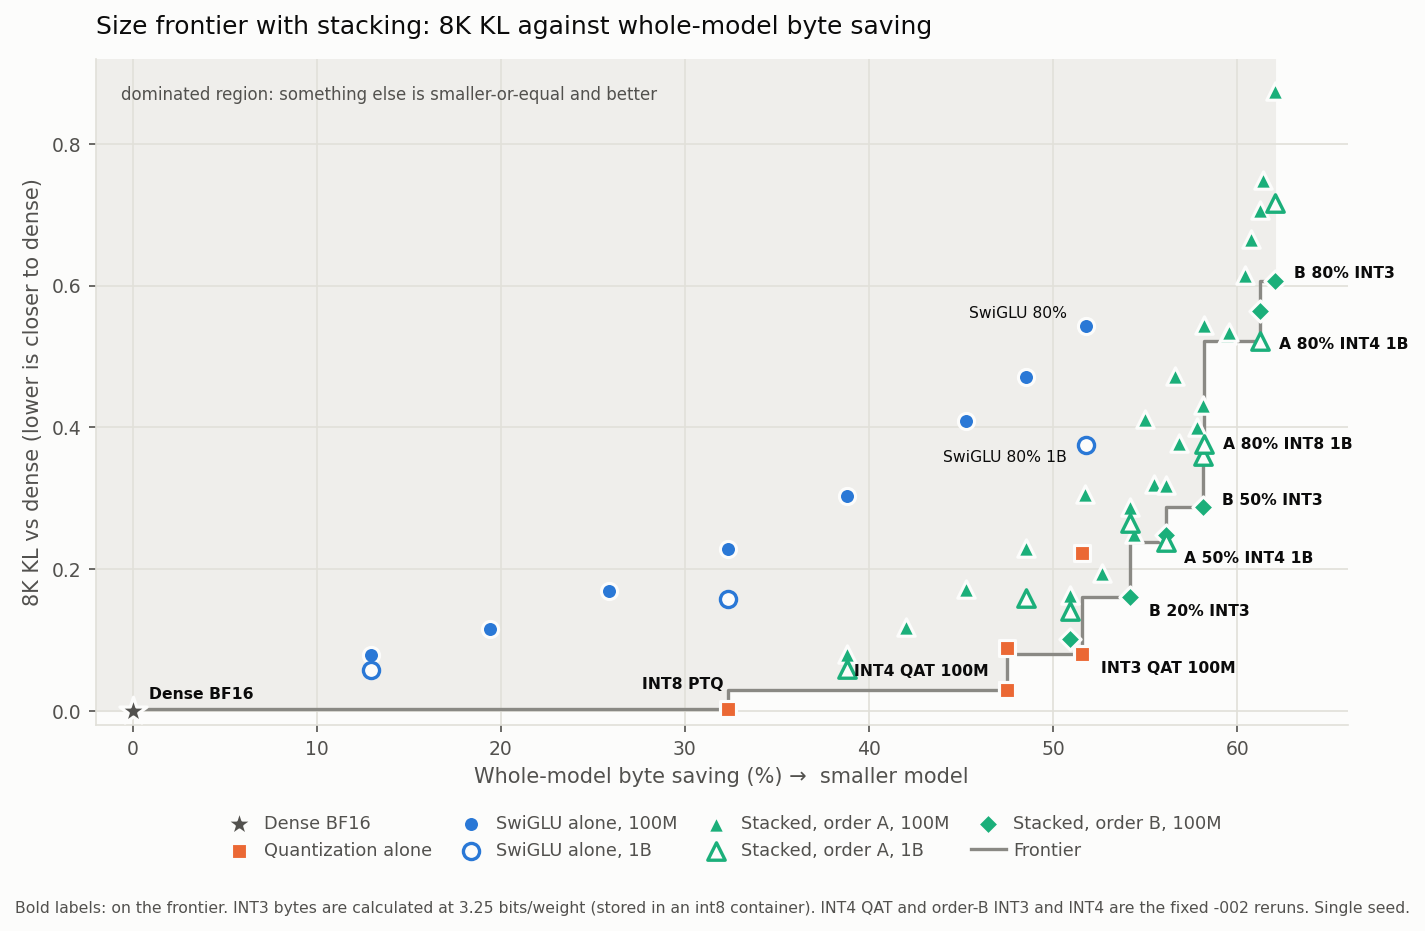

In [10]:
def plot_size_frontier(points, metric, title, ylabel, note, labels, xlim, ylim, filename,
                       xlabel='Whole-model byte saving (%) →  smaller model'):
    on_frontier = points[points[f'frontier_{metric}']].sort_values('byte_saving')

    fig, ax = plt.subplots(figsize=(9.6, 6.2), dpi=FIGURE_DPI)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)
    ax.set_title(title, loc='left', color=TEXT, fontsize=12, pad=12)
    ax.set_xlabel(xlabel, color=TEXT_SECONDARY, fontsize=10)
    ax.set_ylabel(ylabel, color=TEXT_SECONDARY, fontsize=10)

    # Staircase: the best value reachable while saving at least as many bytes.
    staircase_x, staircase_y = [], []
    for index, point in enumerate(on_frontier.itertuples()):
        x, y = 100 * point.byte_saving, getattr(point, metric)
        if index:
            staircase_x.append(staircase_x[-1])
            staircase_y.append(y)
        staircase_x.append(x)
        staircase_y.append(y)
    worst = ylim[1] if FRONTIER_METRICS[metric] else ylim[0]
    ax.fill_between([xlim[0]] + staircase_x, [staircase_y[0]] + staircase_y, worst, color=DOMINATED_FILL, zorder=0)
    ax.plot(staircase_x, staircase_y, color=FRONTIER, linewidth=1.6, zorder=1, label='Frontier')
    ax.text(0.02, 0.96 if FRONTIER_METRICS[metric] else 0.04, 'dominated region: something else is smaller-or-equal and better',
            transform=ax.transAxes, ha='left', va='top' if FRONTIER_METRICS[metric] else 'bottom', fontsize=8, color=TEXT_SECONDARY)

    for label, selector, color, marker, size, filled in SERIES:
        members = points[selector(points)]
        ax.scatter(
            100 * members['byte_saving'], members[metric], s=size, marker=marker,
            facecolor=color if filled else SURFACE, edgecolor=SURFACE if filled else color,
            linewidth=1.5 if filled else 1.6, zorder=3 if filled else 4, label=label,
        )

    for point in points.itertuples():
        if point.variant not in labels:
            continue
        offset_x, offset_y = labels[point.variant]
        ax.annotate(
            point.variant, (100 * point.byte_saving, getattr(point, metric)), xytext=(offset_x, offset_y),
            textcoords='offset points', fontsize=7.5, color=TEXT,
            fontweight='bold' if getattr(point, f'frontier_{metric}') else 'normal',
            ha='left' if offset_x >= 0 else 'right', va='center', zorder=5,
        )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    # Legend columns pair each method's 100M and 1B series.
    handles = dict(zip(*reversed(ax.get_legend_handles_labels())))
    legend_order = [label for label, *_ in SERIES] + ['Frontier']
    ax.legend([handles[label] for label in legend_order], legend_order, loc='upper center', bbox_to_anchor=(0.5, -0.11),
              ncol=4, frameon=False, fontsize=8.5, labelcolor=TEXT_SECONDARY, handletextpad=0.4, columnspacing=1.2)
    fig.text(0.01, 0.01, note, fontsize=7.5, color=TEXT_SECONDARY)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIRECTORY / filename, facecolor=SURFACE)
    plt.show()


print('KL frontier:', list(candidates.loc[candidates['frontier_kl_8k']].sort_values('byte_saving')['variant']))
plot_size_frontier(
    candidates,
    'kl_8k',
    'Size frontier with stacking: 8K KL against whole-model byte saving',
    '8K KL vs dense (lower is closer to dense)',
    'Bold labels: on the frontier. INT3 bytes are calculated at 3.25 bits/weight (stored in an int8 container). '
    'INT4 QAT and order-B INT3 and INT4 are the fixed -002 reruns. Single seed.',
    {
        'Dense BF16': (8, 8),
        'INT8 PTQ': (-2, 12),
        'INT4 QAT 100M': (-9, 9),
        'INT3 QAT 100M': (9, -7),
        'B 20% INT3': (9, -7),
        'A 50% INT4 1B': (9, -8),
        'B 50% INT3': (9, 3),
        'A 80% INT8 1B': (9, 0),
        'A 80% INT4 1B': (9, -2),
        'B 80% INT3': (9, 4),
        'SwiGLU 80%': (-9, 6),
        'SwiGLU 80% 1B': (-9, -6),
    },
    (-2, 66),
    (-0.02, 0.92),
    'frontier-size-kl.png',
)

size frontier, macro accuracy

macro frontier: ['Dense BF16', 'INT4 QAT 1B', 'INT3 QAT 100M', 'A 20% INT3 1B', 'A 50% INT4 1B', 'A 50% INT3 1B', 'A 60% INT3', 'A 70% INT4', 'A 70% INT3', 'A 80% INT4 1B', 'A 80% INT3 1B']


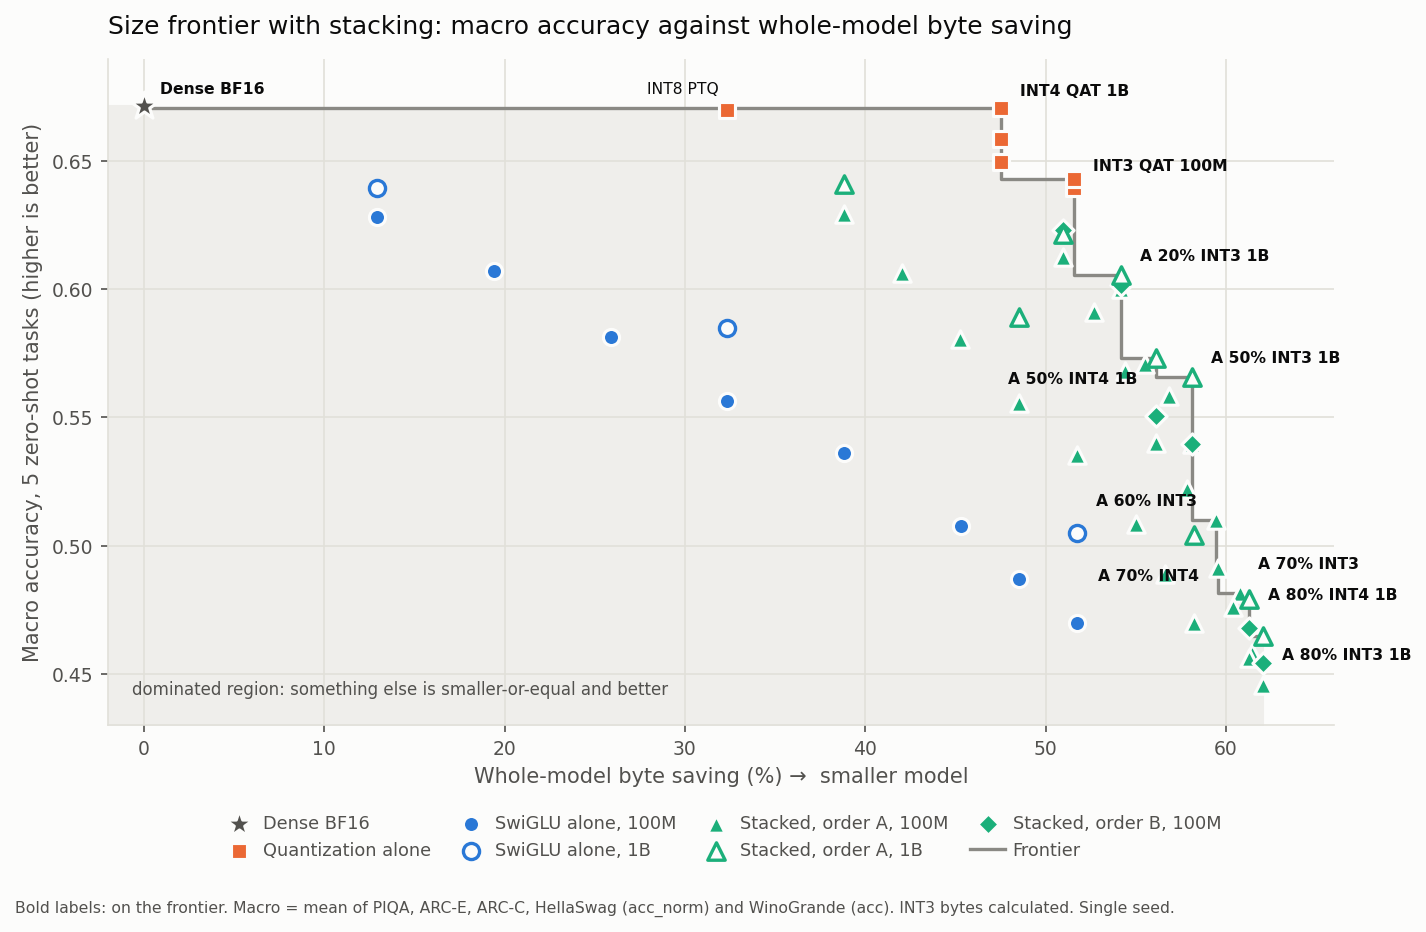

In [11]:
print('macro frontier:', list(candidates.loc[candidates['frontier_macro']].sort_values('byte_saving')['variant']))
plot_size_frontier(
    candidates,
    'macro',
    'Size frontier with stacking: macro accuracy against whole-model byte saving',
    'Macro accuracy, 5 zero-shot tasks (higher is better)',
    'Bold labels: on the frontier. Macro = mean of PIQA, ARC-E, ARC-C, HellaSwag (acc_norm) and WinoGrande (acc). '
    'INT3 bytes calculated. Single seed.',
    {
        'Dense BF16': (8, 8),
        'INT8 PTQ': (-4, 10),
        'INT4 QAT 1B': (9, 8),
        'INT3 QAT 100M': (9, 6),
        'A 20% INT3 1B': (9, 9),
        'A 50% INT4 1B': (-9, -10),
        'A 50% INT3 1B': (9, 9),
        'A 60% INT3': (-9, 9),
        'A 70% INT4': (-9, -4),
        'A 70% INT3': (9, 14),
        'A 80% INT4 1B': (9, 2),
        'A 80% INT3 1B': (9, -9),
    },
    (-2, 66),
    (0.43, 0.69),
    'frontier-size-macro.png',
)


order A against order B at 100M

In [12]:
fitted_100m = variants[(variants['method'] == 'stacked') & (variants['arm'] == 'fitted') & (variants['budget'] == '100M')]
order_rows = []
for bits in ('INT4', 'INT3'):
    for target in ONE_BILLION_TARGETS:
        pair = fitted_100m[(fitted_100m['bits'] == bits) & (fitted_100m['target'] == target)].set_index('order')
        order_rows.append({
            'model': f'SwiGLU {percent_label(target)} + {bits}',
            'byte_saving': pair.loc['A', 'byte_saving'],
            'kl_A': pair.loc['A', 'kl_8k'], 'kl_B': pair.loc['B', 'kl_8k'],
            'kl_B_vs_A': pair.loc['B', 'kl_8k'] / pair.loc['A', 'kl_8k'] - 1,
            'ppl_A': pair.loc['A', 'test_ppl_8k'], 'ppl_B': pair.loc['B', 'test_ppl_8k'],
            'macro_A': pair.loc['A', 'macro'], 'macro_B': pair.loc['B', 'macro'],
            'macro_B_minus_A_pp': 100 * (pair.loc['B', 'macro'] - pair.loc['A', 'macro']),
        })
order_table = pd.DataFrame(order_rows)
order_table.round({'byte_saving': 4, 'kl_A': 4, 'kl_B': 4, 'kl_B_vs_A': 3, 'ppl_A': 2, 'ppl_B': 2, 'macro_A': 4, 'macro_B': 4, 'macro_B_minus_A_pp': 2})

,model,byte_saving,kl_A,kl_B,kl_B_vs_A,ppl_A,ppl_B,macro_A,macro_B,macro_B_minus_A_pp
0,SwiGLU 20% + INT4,0.5095,0.1642,0.1023,-0.377,8.28,8.00,0.6127,0.6230,1.04
1,SwiGLU 50% + INT4,0.5611,0.3185,0.2485,-0.220,10.52,9.88,0.5402,0.5505,1.02
2,SwiGLU 80% + INT4,0.6126,0.7066,0.5645,-0.201,17.49,15.39,0.4562,0.4678,1.16
3,SwiGLU 20% + INT3,0.5418,0.2876,0.1612,-0.439,9.46,8.68,0.6001,0.6015,0.14
4,SwiGLU 50% + INT3,0.5813,0.4323,0.2881,-0.333,11.91,10.50,0.5395,0.5395,-0.01
5,SwiGLU 80% + INT3,0.6207,0.8752,0.6064,-0.307,21.48,16.29,0.4456,0.4541,0.85


local fitting: the gap on the 8K KL at 100M and at 1B

In [13]:
def gap(slice_value, fitted_value):
    return slice_value / fitted_value - 1


swiglu = variants[variants['method'] == 'swiglu'].set_index(['budget', 'arm', 'target'])
summary = load_result(PART_B_SUMMARY)['results']
twin_noise = summary['noise']['value']
gap_rows = []
for target in SWIGLU_TARGETS:
    row = {
        'target': percent_label(target),
        'byte_saving': swiglu.loc[('100M', 'fitted', target), 'byte_saving'],
        'kl_fitted_100m': swiglu.loc[('100M', 'fitted', target), 'kl_8k'],
        'kl_slice_100m': swiglu.loc[('100M', 'slice', target), 'kl_8k'],
        'gap_100m': gap(swiglu.loc[('100M', 'slice', target), 'kl_8k'], swiglu.loc[('100M', 'fitted', target), 'kl_8k']),
    }
    if target in ONE_BILLION_TARGETS:
        fitted_kl, slice_kl = swiglu.loc[('1B', 'fitted', target), 'kl_8k'], swiglu.loc[('1B', 'slice', target), 'kl_8k']
        row.update({
            'kl_fitted_1b': fitted_kl, 'kl_slice_1b': slice_kl, 'gap_1b': gap(slice_kl, fitted_kl),
            'absolute_gap_1b': slice_kl - fitted_kl,
            'summary_gap_1b': summary['targets'][target]['gap'], 'verdict': summary['targets'][target]['verdict'],
        })
    gap_rows.append(row)
gap_table = pd.DataFrame(gap_rows)
print('twin noise:', round(twin_noise, 5), '| noise valid:', summary['noise_valid'],
      '| gap at 50% with the twin as the fitted model:', round(summary['twin']['gap_with_twin_at_0.5'], 5))
gap_table.round(5)

twin noise: 0.00313 | noise valid: True | gap at 50% with the twin as the fitted model: 0.01809


,target,byte_saving,kl_fitted_100m,kl_slice_100m,gap_100m,kl_fitted_1b,kl_slice_1b,gap_1b,absolute_gap_1b,summary_gap_1b,verdict
0,20%,0.12940,0.07875,0.08865,0.12576,0.05821,0.05983,0.02772,0.00161,0.02772,closed
1,30%,0.19411,0.11609,0.12880,0.10947,NaN,NaN,NaN,NaN,NaN,NaN
2,40%,0.25881,0.17006,0.18829,0.10721,NaN,NaN,NaN,NaN,NaN,NaN
3,50%,0.32351,0.22885,0.25268,0.10414,0.15779,0.16067,0.01829,0.00289,0.01829,closed
4,60%,0.38821,0.30400,0.33570,0.10430,NaN,NaN,NaN,NaN,NaN,NaN
5,70%,0.45292,0.40945,0.45488,0.11096,NaN,NaN,NaN,NaN,NaN,NaN
6,75%,0.48527,0.47072,0.58152,0.23539,NaN,NaN,NaN,NaN,NaN,NaN
7,80%,0.51762,0.54325,0.64319,0.18396,0.37523,0.37648,0.00334,0.00125,0.00334,closed


In [14]:
# Under quantization: order A on SwiGLU-8's 100M models; the BF16 rows are those models unquantized.
FORMATS = ['BF16', 'INT8', 'INT4', 'INT3']
arms_100m = pd.concat([
    variants[(variants['method'] == 'swiglu') & (variants['budget'] == '100M')].assign(bits='BF16'),
    variants[(variants['method'] == 'stacked') & (variants['order'] == 'A') & (variants['budget'] == '100M')],
]).set_index(['arm', 'bits', 'target'])
quantized_gaps = pd.DataFrame([
    {
        'target': percent_label(target), 'format': bits,
        'kl_fitted': arms_100m.loc[('fitted', bits, target), 'kl_8k'], 'kl_slice': arms_100m.loc[('slice', bits, target), 'kl_8k'],
        'gap': gap(arms_100m.loc[('slice', bits, target), 'kl_8k'], arms_100m.loc[('fitted', bits, target), 'kl_8k']),
        'absolute_gap': arms_100m.loc[('slice', bits, target), 'kl_8k'] - arms_100m.loc[('fitted', bits, target), 'kl_8k'],
        'macro_slice_minus_fitted_pp': 100 * (arms_100m.loc[('slice', bits, target), 'macro'] - arms_100m.loc[('fitted', bits, target), 'macro']),
    }
    for target in ONE_BILLION_TARGETS for bits in FORMATS
])
quantized_gaps.round(4)

,target,format,kl_fitted,kl_slice,gap,absolute_gap,macro_slice_minus_fitted_pp
0,20%,BF16,0.0787,0.0887,0.1258,0.0099,-0.9444
1,20%,INT8,0.0805,0.0904,0.1231,0.0099,-0.7756
2,20%,INT4,0.1642,0.1770,0.0778,0.0128,-0.7525
3,20%,INT3,0.2876,0.2903,0.0094,0.0027,0.1758
4,50%,BF16,0.2288,0.2527,0.1041,0.0238,-0.1759
5,50%,INT8,0.2306,0.2535,0.0992,0.0229,-0.0834
6,50%,INT4,0.3185,0.3551,0.1149,0.0366,-0.2413
7,50%,INT3,0.4323,0.4413,0.0210,0.0091,-0.4242
8,80%,BF16,0.5433,0.6432,0.1840,0.0999,-1.3809
9,80%,INT8,0.5444,0.6446,0.1841,0.1002,-1.5544


local fitting, figure: the 8K-KL gap

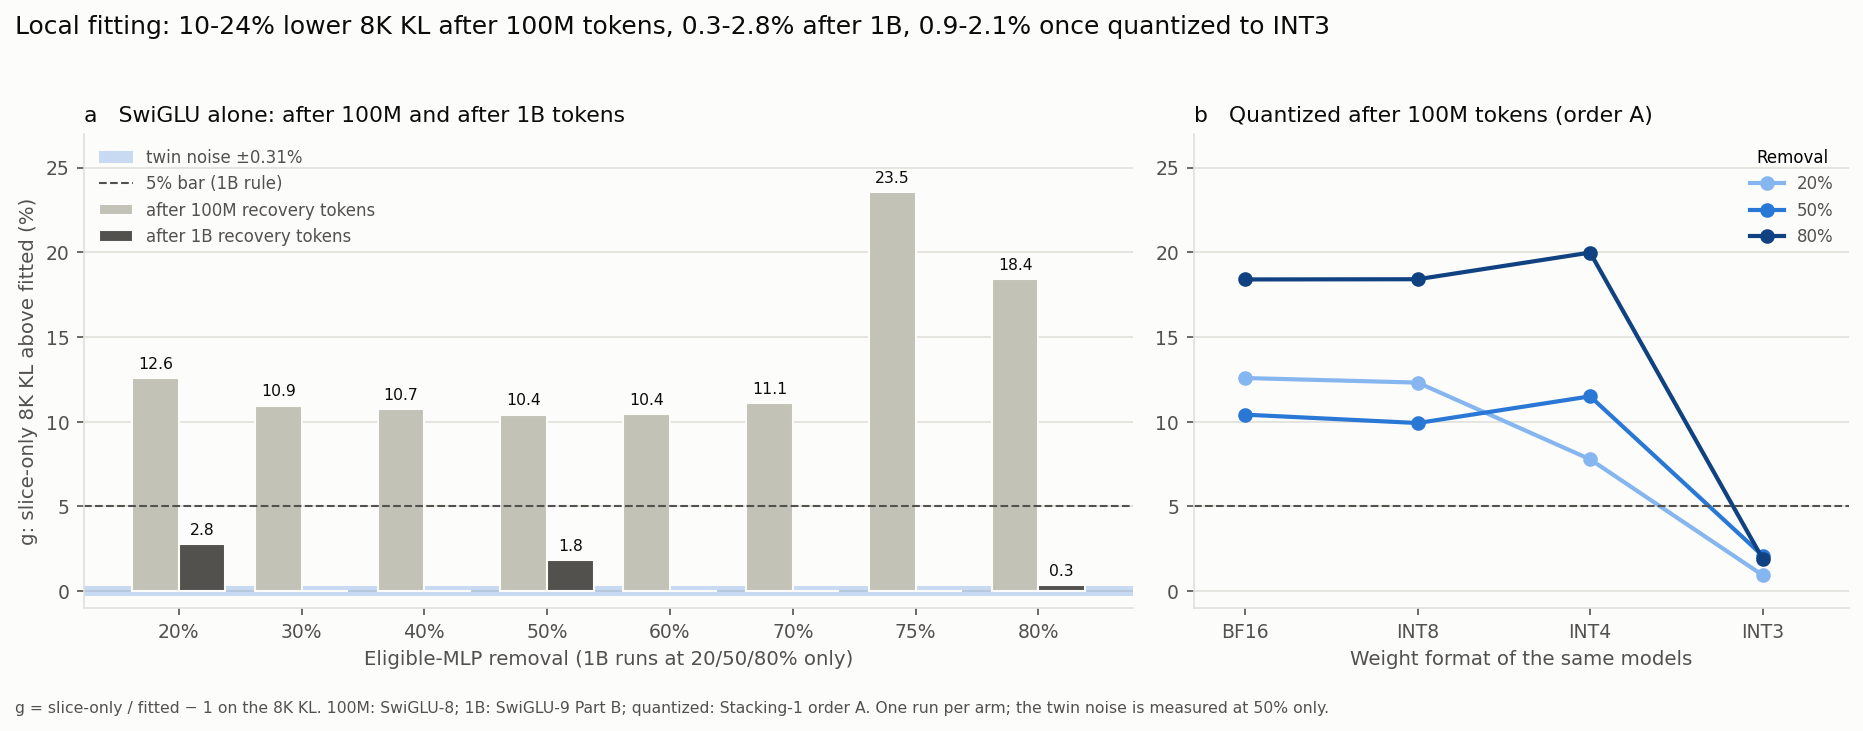

In [15]:
TARGET_COLORS = {'0.2': '#86b6ef', '0.5': '#2a78d6', '0.8': '#104281'}  # ordinal blue ramp (dataviz validator, light)
BUDGET_COLORS = {'100M': '#c3c2b7', '1B': '#52514e'}


def style_axis(axis, title, ylabel, xlabel):
    axis.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        axis.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        axis.spines[side].set_color(GRID)
    axis.grid(True, axis='y', color=GRID, linewidth=0.8)
    axis.set_axisbelow(True)
    axis.tick_params(colors=TEXT_SECONDARY, labelsize=9)
    axis.set_title(title, loc='left', color=TEXT, fontsize=10.5)
    axis.set_ylabel(ylabel, color=TEXT_SECONDARY, fontsize=9.5)
    axis.set_xlabel(xlabel, color=TEXT_SECONDARY, fontsize=9.5)


figure, (budget_axis, format_axis) = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=FIGURE_DPI, gridspec_kw={'width_ratios': (1.6, 1)})
figure.patch.set_facecolor(SURFACE)
GAP_LIMITS = (-1, 27)

positions = list(range(len(gap_table)))
bar_width = 0.38
budget_axis.axhspan(-100 * twin_noise, 100 * twin_noise, color=TARGET_COLORS['0.5'], alpha=0.25, linewidth=0,
                    label=f'twin noise ±{twin_noise:.2%}')
budget_axis.axhline(100 * GAP_BAR, color=TEXT_SECONDARY, linestyle='--', linewidth=1, label=f'{GAP_BAR:.0%} bar (1B rule)')
for offset, budget, column in ((-bar_width / 2, '100M', 'gap_100m'), (bar_width / 2, '1B', 'gap_1b')):
    values = 100 * gap_table[column]
    xs = [position + offset for position in positions]
    budget_axis.bar(xs, values.fillna(0), width=bar_width, color=BUDGET_COLORS[budget], edgecolor=SURFACE, linewidth=1,
                    label=f'after {budget} recovery tokens')
    for x, value in zip(xs, values):
        if pd.notna(value):
            budget_axis.text(x, value + 0.4, f'{value:.1f}', ha='center', va='bottom', fontsize=7.5, color=TEXT)
budget_axis.set_xticks(positions, gap_table['target'])
budget_axis.set_ylim(*GAP_LIMITS)
style_axis(budget_axis, 'a   SwiGLU alone: after 100M and after 1B tokens', 'g: slice-only 8K KL above fitted (%)',
           'Eligible-MLP removal (1B runs at 20/50/80% only)')
budget_axis.legend(loc='upper left', frameon=False, fontsize=8, labelcolor=TEXT_SECONDARY)

for target in ONE_BILLION_TARGETS:
    rows = quantized_gaps[quantized_gaps['target'] == percent_label(target)].set_index('format').loc[FORMATS]
    format_axis.plot(FORMATS, 100 * rows['gap'], color=TARGET_COLORS[target], marker='o', markersize=6, linewidth=2,
                     label=percent_label(target))
format_axis.axhline(100 * GAP_BAR, color=TEXT_SECONDARY, linestyle='--', linewidth=1)
format_axis.set_ylim(*GAP_LIMITS)
format_axis.set_xlim(-0.3, len(FORMATS) - 0.5)
style_axis(format_axis, 'b   Quantized after 100M tokens (order A)', '', 'Weight format of the same models')
format_axis.legend(title='Removal', loc='upper right', frameon=False, fontsize=8, title_fontsize=8, labelcolor=TEXT_SECONDARY)

figure.suptitle(
    f"Local fitting: {100 * gap_table['gap_100m'].min():.0f}-{100 * gap_table['gap_100m'].max():.0f}% lower 8K KL after 100M tokens, "
    f"{100 * gap_table['gap_1b'].min():.1f}-{100 * gap_table['gap_1b'].max():.1f}% after 1B, "
    f"{100 * quantized_gaps.loc[quantized_gaps['format'] == 'INT3', 'gap'].min():.1f}-"
    f"{100 * quantized_gaps.loc[quantized_gaps['format'] == 'INT3', 'gap'].max():.1f}% once quantized to INT3",
    x=0.01, ha='left', color=TEXT, fontsize=12,
)
figure.text(0.01, 0.01, 'g = slice-only / fitted − 1 on the 8K KL. 100M: SwiGLU-8; 1B: SwiGLU-9 Part B; quantized: Stacking-1 order A. '
            'One run per arm; the twin noise is measured at 50% only.', fontsize=7.5, color=TEXT_SECONDARY)
figure.tight_layout(rect=(0, 0.04, 1, 0.95))
if SAVE_FIGURES:
    figure.savefig(FIGURE_DIRECTORY / 'local-fit-gap.png', facecolor=SURFACE)
plt.show()

local fitting: cost of the fit, token equivalents, and net saving (monitoring KL)

In [16]:
fits = {(fit['layer'], fit['replacement_width']): fit['fit_seconds'] for fit in prepare['local_fitting']}
fit_minutes = {
    target: sum(fits[(row['layer'], row['replacement_width'])] for row in prepare['starts'][f'fitted:{target}']['allocation']
                if not row['retains_dense_module']) / 60
    for target in SWIGLU_TARGETS
}
# As SwiGLU-9's notebook: the fit time converted to recovery tokens at the slice-only 1B run's throughput.
slice_recovery = {target: load_result(relative)['results']['recovery'] for target, relative in SWIGLU_1B_SLICE_RUNS.items()}
fit_cost_tokens = {
    target: 60 * fit_minutes[target] * slice_recovery[target]['tokens_seen'] / slice_recovery[target]['training_seconds']
    for target in ONE_BILLION_TARGETS
}
pd.DataFrame({'fit GPU-minutes (fit time only, without pair capture)': fit_minutes,
              'fit cost (M recovery tokens)': {target: value / 1e6 for target, value in fit_cost_tokens.items()}}).round(1)

,"fit GPU-minutes (fit time only, without pair capture)",fit cost (M recovery tokens)
0.2,4.3,7.0
0.3,6.6,NaN
0.4,10.1,NaN
0.5,15.5,26.3
0.6,23.4,NaN
0.7,33.7,NaN
0.75,36.9,NaN
0.8,41.7,77.0


In [17]:
# Token equivalent T(t): the first point at which the slice-only run reaches the fitted run's monitoring KL at t
# (SwiGLU-9 summary, linear interpolation). Net saving N(t) = T(t) - t - fit cost, SwiGLU-9's project-defined measure.
# Where T(t) is not reached within 1B, only a lower bound exists.
net_rows = []
for target in ONE_BILLION_TARGETS:
    final_tokens = slice_recovery[target]['tokens_seen']
    for point in summary['targets'][target]['token_equivalent']:
        reached = point['slice_tokens'] is not None
        head_start = (point['slice_tokens'] if reached else final_tokens) - point['fitted_tokens']
        net_rows.append({
            'target': target, 'fitted_tokens': point['fitted_tokens'], 'slice_tokens': point['slice_tokens'],
            'reached': reached, 'head_start': head_start, 'net_saving': head_start - fit_cost_tokens[target],
        })
net_saving = pd.DataFrame(net_rows)

TOKEN_POINTS = [100_000_000, 500_000_000, 1_000_000_000]
token_table = pd.DataFrame([
    {'target': percent_label(target), 'fitted_tokens_M': tokens / 1e6} | {
        key: row[column] / 1e6 if row['reached'] else None
        for key, column in (('slice_tokens_M', 'slice_tokens'), ('head_start_M', 'head_start'), ('net_saving_M', 'net_saving'))
    }
    for target in ONE_BILLION_TARGETS for tokens in TOKEN_POINTS
    for row in [net_saving[net_saving['target'] == target].iloc[(net_saving[net_saving['target'] == target]['fitted_tokens'] - tokens).abs().argmin()]]
])
token_table.round(1)

,target,fitted_tokens_M,slice_tokens_M,head_start_M,net_saving_M
0,20%,100.0,295.6,195.6,188.6
1,20%,500.0,537.1,37.1,30.1
2,20%,1000.0,NaN,NaN,NaN
3,50%,100.0,173.7,73.7,47.4
4,50%,500.0,676.5,176.5,150.2
5,50%,1000.0,NaN,NaN,NaN
6,80%,100.0,177.2,77.2,0.2
7,80%,500.0,537.0,37.0,-39.9
8,80%,1000.0,929.0,-71.0,-148.0


local fitting, figure: how the gap closes and what the fit saves

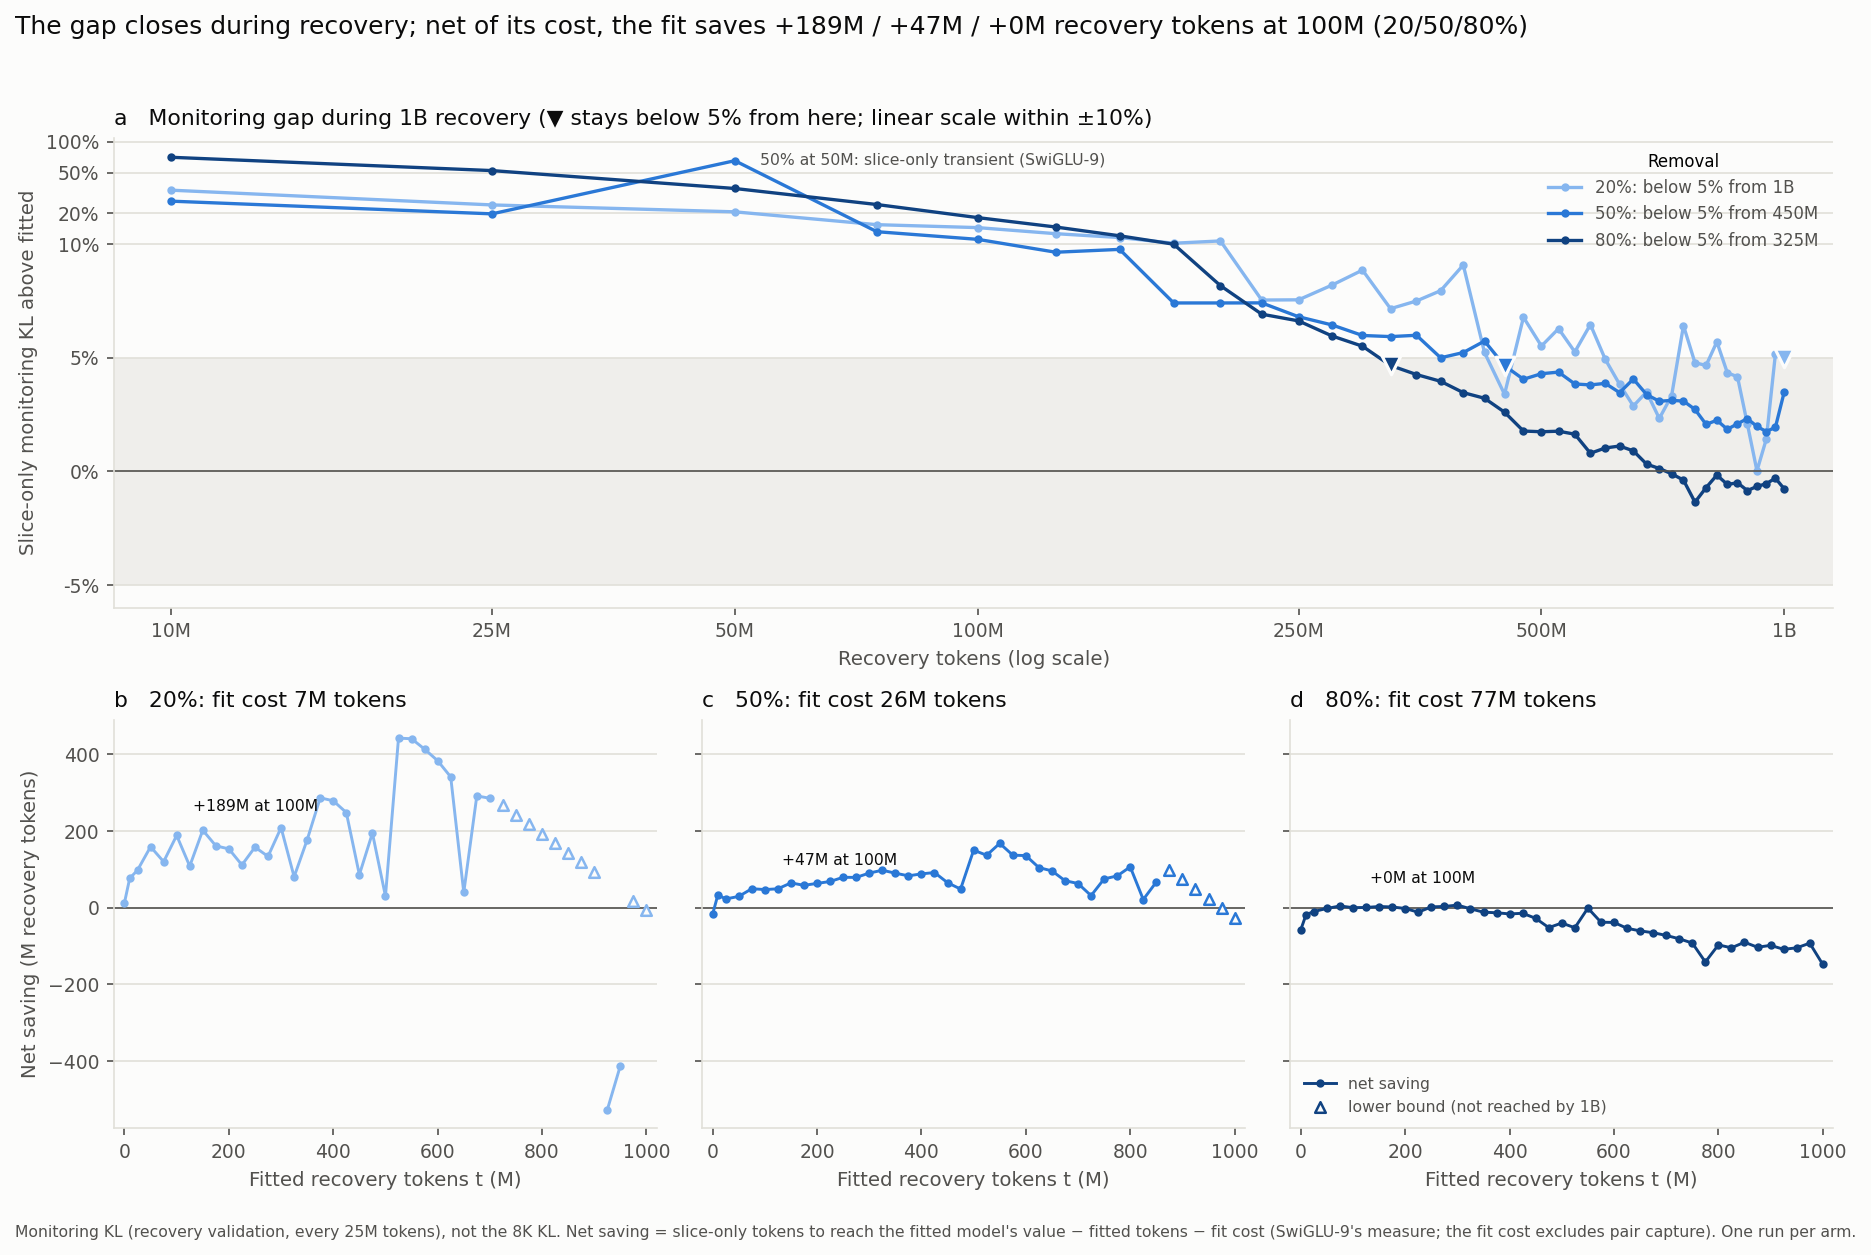

In [18]:
def token_label(value, _=None):
    return f'{value / 1e9:g}B' if value >= 1e9 else f'{value / 1e6:.0f}M'


figure = plt.figure(figsize=(12.5, 8.4), dpi=FIGURE_DPI)
figure.patch.set_facecolor(SURFACE)
grid = figure.add_gridspec(2, 3, height_ratios=(1.15, 1))
curve_axis = figure.add_subplot(grid[0, :])
saving_axes = [figure.add_subplot(grid[1, 0])]
saving_axes += [figure.add_subplot(grid[1, column], sharey=saving_axes[0]) for column in (1, 2)]

curve_axis.axhspan(-100 * GAP_BAR, 100 * GAP_BAR, color=DOMINATED_FILL, linewidth=0, zorder=0)
for target in ONE_BILLION_TARGETS:
    curve = pd.DataFrame(summary['targets'][target]['gap_curve'])
    curve = curve[curve['tokens'] > 0]
    closing = summary['targets'][target]['closing_point_tokens']
    curve_axis.plot(curve['tokens'], 100 * curve['gap'], color=TARGET_COLORS[target], marker='o', markersize=3, linewidth=1.6,
                    label=f"{percent_label(target)}: below {GAP_BAR:.0%} from {'never' if closing is None else token_label(closing)}")
    if closing is not None:
        curve_axis.scatter(closing, 100 * curve.loc[curve['tokens'] == closing, 'gap'].iloc[0], marker='v', s=80,
                           color=TARGET_COLORS[target], edgecolor=SURFACE, linewidth=1.5, zorder=5)
transient = pd.DataFrame(summary['targets']['0.5']['gap_curve']).set_index('tokens').iloc[3]
curve_axis.annotate('50% at 50M: slice-only transient (SwiGLU-9)', (transient.name, 100 * transient['gap']), xytext=(12, 0),
                    textcoords='offset points', va='center', fontsize=7.5, color=TEXT_SECONDARY)
curve_axis.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
curve_axis.set_xscale('log')
curve_axis.set_xlim(8.5e6, 1.15e9)
curve_axis.xaxis.set_major_locator(FixedLocator([1e7, 2.5e7, 5e7, 1e8, 2.5e8, 5e8, 1e9]))
curve_axis.xaxis.set_major_formatter(FuncFormatter(token_label))
curve_axis.xaxis.set_minor_locator(NullLocator())
curve_axis.set_yscale('symlog', linthresh=10, linscale=2)
curve_axis.yaxis.set_major_locator(FixedLocator([-5, 0, 5, 10, 20, 50, 100]))
curve_axis.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:g}%'))
curve_axis.yaxis.set_minor_locator(NullLocator())
curve_axis.set_ylim(-6, 110)
style_axis(curve_axis, f'a   Monitoring gap during 1B recovery (▼ stays below {GAP_BAR:.0%} from here; linear scale within ±10%)',
           'Slice-only monitoring KL above fitted', 'Recovery tokens (log scale)')
curve_axis.legend(title='Removal', loc='upper right', frameon=False, fontsize=8, title_fontsize=8, labelcolor=TEXT_SECONDARY)

for axis, letter, target in zip(saving_axes, 'bcd', ONE_BILLION_TARGETS):
    rows = net_saving[net_saving['target'] == target]
    bound = rows[~rows['reached']]
    axis.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
    # NaN breaks the line where the slice-only run does not reach the fitted value within 1B.
    axis.plot(rows['fitted_tokens'] / 1e6, rows['net_saving'].where(rows['reached']) / 1e6, color=TARGET_COLORS[target],
              marker='o', markersize=3, linewidth=1.4, label='net saving')
    axis.scatter(bound['fitted_tokens'] / 1e6, bound['net_saving'] / 1e6, marker='^', facecolor=SURFACE,
                 edgecolor=TARGET_COLORS[target], s=26, linewidth=1.2, zorder=4, label='lower bound (not reached by 1B)')
    at_100m = rows.loc[rows['fitted_tokens'] == 100_000_000, 'net_saving'].iloc[0]
    axis.annotate(f'{at_100m / 1e6:+.0f}M at 100M', (100, at_100m / 1e6), xytext=(8, 12), textcoords='offset points',
                  fontsize=7.5, color=TEXT)
    axis.set_xlim(-20, 1020)
    style_axis(axis, f'{letter}   {percent_label(target)}: fit cost {fit_cost_tokens[target] / 1e6:.0f}M tokens',
               'Net saving (M recovery tokens)' if letter == 'b' else '', 'Fitted recovery tokens t (M)')
saving_axes[2].legend(loc='lower left', frameon=False, fontsize=7.5, labelcolor=TEXT_SECONDARY)
for axis in saving_axes[1:]:
    axis.tick_params(labelleft=False)

net_100m = net_saving[net_saving['fitted_tokens'] == 100_000_000].set_index('target')['net_saving']
figure.suptitle('The gap closes during recovery; net of its cost, the fit saves '
                + ' / '.join(f'{value / 1e6:+.0f}M' for value in net_100m) + ' recovery tokens at 100M (20/50/80%)',
                x=0.01, ha='left', color=TEXT, fontsize=12)
figure.text(0.01, 0.01, 'Monitoring KL (recovery validation, every 25M tokens), not the 8K KL. Net saving = slice-only tokens to reach '
            "the fitted model's value − fitted tokens − fit cost (SwiGLU-9's measure; the fit cost excludes pair capture). One run per arm.",
            fontsize=7.5, color=TEXT_SECONDARY)
figure.tight_layout(rect=(0, 0.03, 1, 0.96))
if SAVE_FIGURES:
    figure.savefig(FIGURE_DIRECTORY / 'local-fit-recovery.png', facecolor=SURFACE)
plt.show()

In [19]:
# The 2026-10-15 snapshot's "about 51-87M tokens (30-54 GPU-minutes)" answers the reverse question on SwiGLU-8's 100M
# runs: how much earlier the fitted model reaches the slice-only model's 100M monitoring KL. Its method was not
# recorded; interpolating linearly in log tokens between checkpoints reproduces it.
def log_token_crossing(history, level):
    for before, after in zip(history, history[1:]):
        if before['recovery_validation_kl'] > level >= after['recovery_validation_kl']:
            fraction = (before['recovery_validation_kl'] - level) / (before['recovery_validation_kl'] - after['recovery_validation_kl'])
            return math.exp(math.log(before['actual_tokens']) + fraction * (math.log(after['actual_tokens']) - math.log(before['actual_tokens'])))
    return None


reverse_rows = []
for target in SWIGLU_TARGETS:
    fitted_recovery = load_result(f'swiglu-8/fitted-target-{target}-run-001')['results']['recovery']
    slice_history = load_result(f'swiglu-8/slice-target-{target}-run-001')['results']['recovery']['validation_history']
    crossing = log_token_crossing(fitted_recovery['validation_history'], slice_history[-1]['recovery_validation_kl'])
    tokens_saved = fitted_recovery['tokens_seen'] - crossing
    reverse_rows.append({
        'target': percent_label(target),
        'fitted_reaches_slice_100m_at_M': crossing / 1e6,
        'tokens_saved_M': tokens_saved / 1e6,
        'gpu_minutes_saved': tokens_saved / fitted_recovery['tokens_seen'] * fitted_recovery['training_seconds'] / 60,
    })
reverse_table = pd.DataFrame(reverse_rows)
reverse_table.round(1)

,target,fitted_reaches_slice_100m_at_M,tokens_saved_M,gpu_minutes_saved
0,20%,13.5,86.5,53.6
1,30%,33.3,66.7,41.8
2,40%,43.7,56.3,34.4
3,50%,49.3,50.7,30.1
4,60%,46.6,53.4,31.6
5,70%,46.0,54.0,31.0
6,75%,20.3,79.7,44.0
7,80%,30.7,69.3,37.8


compute work (supplement)

compute-work frontier: ['Dense BF16', 'SwiGLU 20% 1B', 'SwiGLU 30%', 'SwiGLU 50% 1B', 'SwiGLU 60%', 'SwiGLU 80% 1B']


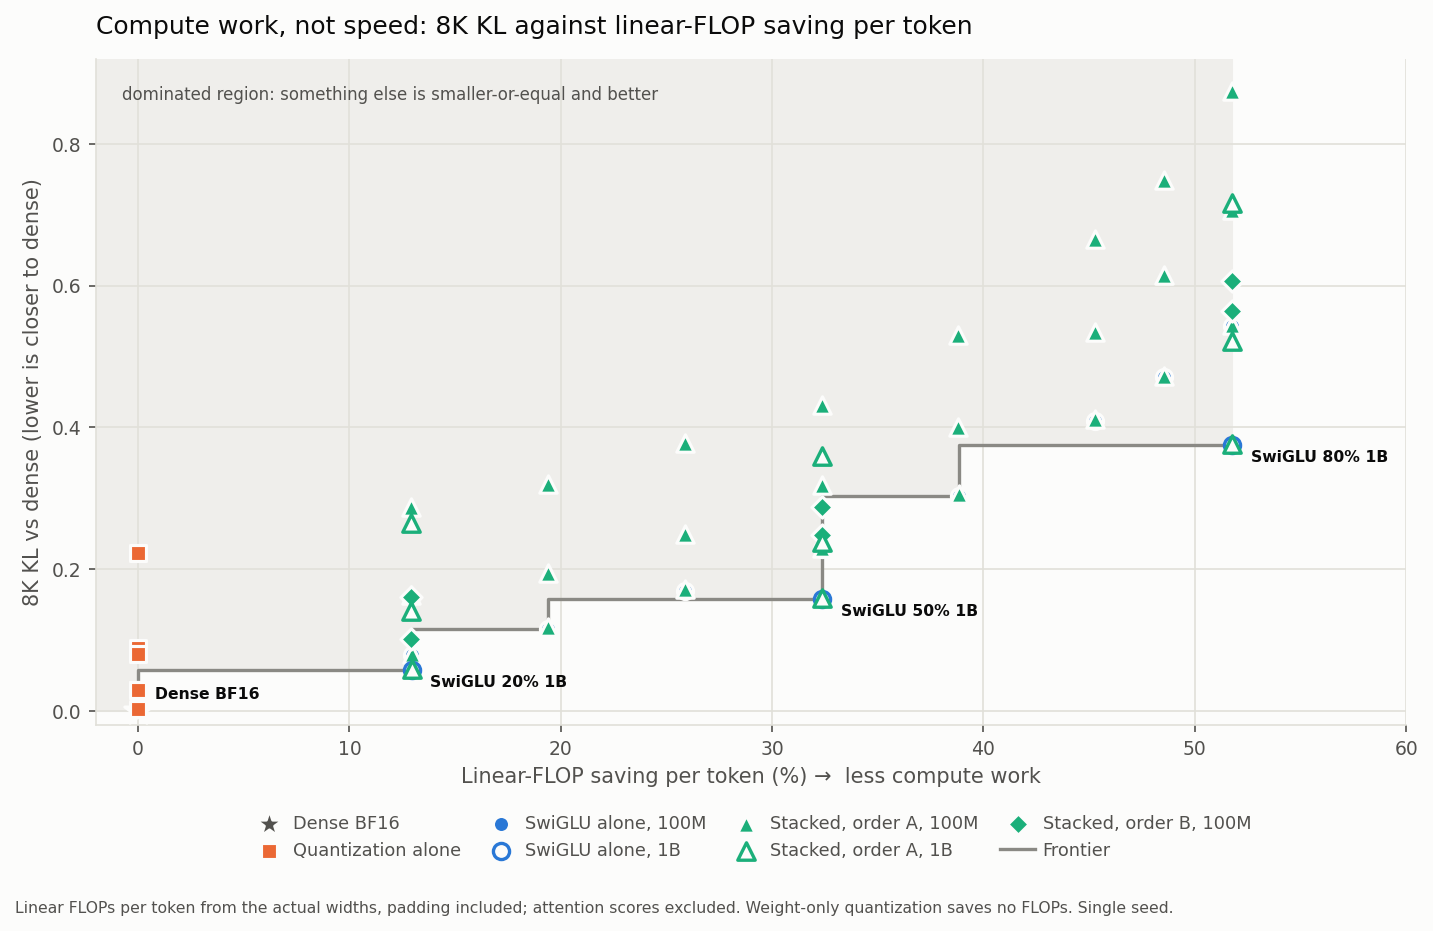

In [20]:
# Supplement (decision log, 2026-11-01): the same models placed by linear-FLOP saving instead of byte saving.
frontier_columns = [column for column in candidates if column.startswith('frontier_')]
compute_points = candidates.drop(columns=frontier_columns).assign(byte_saving=candidates['flop_saving'])
compute_points = compute_points.join(frontier_flags(compute_points).add_prefix('frontier_'))
print('compute-work frontier:', list(compute_points.loc[compute_points['frontier_kl_8k']].sort_values('byte_saving')['variant']))
plot_size_frontier(
    compute_points,
    'kl_8k',
    'Compute work, not speed: 8K KL against linear-FLOP saving per token',
    '8K KL vs dense (lower is closer to dense)',
    'Linear FLOPs per token from the actual widths, padding included; attention scores excluded. '
    'Weight-only quantization saves no FLOPs. Single seed.',
    {'Dense BF16': (8, 8), 'SwiGLU 20% 1B': (9, -6), 'SwiGLU 50% 1B': (9, -6), 'SwiGLU 80% 1B': (9, -6)},
    (-2, 60),
    (-0.02, 0.92),
    'frontier-compute-kl.png',
    xlabel='Linear-FLOP saving per token (%) →  less compute work',
)


cost to produce

In [21]:
def hours(seconds):
    return seconds / 3600


cost_rows = []
for label, relative in QAT_TRAINING_RUNS.items():
    recovery = load_result(relative)['results']['recovery']
    cost_rows.append({'variant': label, 'tokens': recovery['tokens_seen'], 'gpu_hours': hours(recovery['elapsed_seconds']), 'counted': 'QAT training'})
for budget, arm_runs in (('100M', {target: f'swiglu-8/fitted-target-{target}-run-001' for target in SWIGLU_TARGETS}), ('1B', SWIGLU_1B_FITTED_RUNS)):
    for target, relative in arm_runs.items():
        recovery = load_result(relative)['results']['recovery']
        cost_rows.append({'variant': f'SwiGLU {percent_label(target)} {budget}', 'tokens': recovery['tokens_seen'],
                          'gpu_hours': hours(recovery['training_seconds']), 'counted': 'recovery'})
for path in sorted((RESULTS_ROOT / 'stacking-1').glob('*/result.json')):
    name = path.parent.name
    if name in STACKING_SKIPPED:
        continue
    stages = json.loads(path.read_text(encoding='utf-8'))['results']['stage_seconds']
    cost_rows.append({
        'variant': name, 'tokens': 100_000_000 if 'qat_recover' in stages else 0,
        'gpu_hours': hours(stages.get('qat_recover', 0.0)), 'evaluation_hours': hours(stages['evaluate']),
        'counted': 'QAT recovery' if 'qat_recover' in stages else 'PTQ conversion only',
        'invalid': name in STACKING_EXCLUDED,
    })
costs = pd.DataFrame(cost_rows)
costs['invalid'] = costs['invalid'].fillna(False).astype(bool)
print(len(costs), 'cost rows; per-run values are in `costs`')

65 cost rows; per-run values are in `costs`


In [22]:
order_b = costs[costs['variant'].str.startswith('b-') & ~costs['invalid']]
order_a = costs[costs['variant'].str.startswith('a-')]
swiglu_100m = costs[costs['variant'].str.endswith(' 100M') & costs['variant'].str.startswith('SwiGLU')]
swiglu_1b = costs[costs['variant'].str.endswith(' 1B') & costs['variant'].str.startswith('SwiGLU')]
invalid_hours = sum(hours(load_result(relative)['results']['recovery']['elapsed_seconds']) for relative in INVALID_INT3_QAT_RUNS[:2])
invalid_hours += costs.loc[costs['invalid'], 'gpu_hours'].sum()
print(f'SwiGLU 100M recovery: {swiglu_100m.gpu_hours.min():.2f}-{swiglu_100m.gpu_hours.max():.2f} h; with the local fit: '
      f'{min(h + fit_minutes[t] / 60 for h, t in zip(swiglu_100m.gpu_hours, SWIGLU_TARGETS)):.2f}-'
      f'{max(h + fit_minutes[t] / 60 for h, t in zip(swiglu_100m.gpu_hours, SWIGLU_TARGETS)):.2f} h')
print(f'SwiGLU 1B recovery: {swiglu_1b.gpu_hours.min():.2f}-{swiglu_1b.gpu_hours.max():.2f} h')
print(f'order A: PTQ only; evaluation {order_a.evaluation_hours.min():.2f}-{order_a.evaluation_hours.max():.2f} h per model')
print(f'order B QAT recovery: {order_b.gpu_hours.min():.2f}-{order_b.gpu_hours.max():.2f} h per run; '
      f'evaluation {order_b.evaluation_hours.min():.2f}-{order_b.evaluation_hours.max():.2f} h')
print(f'invalid INT3 QAT -001 runs (not counted above): {invalid_hours:.2f} h of training')

SwiGLU 100M recovery: 0.91-1.05 h; with the local fit: 1.10-1.60 h
SwiGLU 1B recovery: 9.08-10.41 h
order A: PTQ only; evaluation 0.21-0.31 h per model
order B QAT recovery: 0.96-1.18 h per run; evaluation 0.21-0.31 h
invalid INT3 QAT -001 runs (not counted above): 17.51 h of training


decision-log conditions

In [23]:
int3_qat = candidates.set_index('variant').loc['INT3 QAT 100M']
smaller_stacked = candidates[(candidates['method'] == 'stacked') & (candidates['byte_saving'] <= int3_qat['byte_saving'])]
closest = smaller_stacked.sort_values('macro', ascending=False).iloc[0]
print('2026-10-26 reopen condition: INT3 QAT 100M macro', round(int3_qat['macro'], 4),
      '| best stacked macro at equal or smaller saving:', closest['variant'], round(closest['macro'], 4),
      f"({100 * closest['byte_saving']:.1f}% saving)")
print('   INT3 QAT 100M is below that stacked model by', round(closest['macro'] - int3_qat['macro'], 4),
      '-> reopen' if 0 < closest['macro'] - int3_qat['macro'] <= REOPEN_MACRO_MARGIN else '-> not met')

int3_ptq = candidates.set_index('variant').loc['INT3 PTQ']
print('2026-10-17 GPTQ condition: INT3 PTQ / INT3 QAT 100M: 8K KL', round(int3_ptq['kl_8k'] / int3_qat['kl_8k'], 2),
      'x; test PPL', round(int3_ptq['test_ppl_8k'] / int3_qat['test_ppl_8k'], 3),
      'x; macro', round(100 * (int3_ptq['macro'] - int3_qat['macro']), 2), 'pp')

2026-10-26 reopen condition: INT3 QAT 100M macro 0.643 | best stacked macro at equal or smaller saving: A 20% INT8 1B 0.641 (38.8% saving)
   INT3 QAT 100M is below that stacked model by -0.0021 -> not met
2026-10-17 GPTQ condition: INT3 PTQ / INT3 QAT 100M: 8K KL 2.77 x; test PPL 1.102 x; macro -0.34 pp
